## Imports and config

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# Plot settings
plt.style.use("seaborn-v0_8")


## Call NASA POWER Function

In [2]:
def fetch_nasa_daily_ghi(lat, lon, start, end):
    """
    Fetch daily GHI from NASA POWER for given lat/lon and date range.
    start, end: YYYYMMDD strings
    """
    base_url = "https://power.larc.nasa.gov/api/temporal/daily/point"
    params = {
        "start": start,
        "end": end,
        "latitude": lat,
        "longitude": lon,
        "parameters": "ALLSKY_SFC_SW_DWN,T2M",
        "community": "RE",
        "format": "JSON"
    }
    r = requests.get(base_url, params=params)
    r.raise_for_status()
    data = r.json()

    records = data["properties"]["parameter"]["ALLSKY_SFC_SW_DWN"]
    temps = data["properties"]["parameter"]["T2M"]

    df = pd.DataFrame({
        "date": list(records.keys()),
        "ghi_kwh_m2": list(records.values()),
    })
    df["temp_c"] = df["date"].map(temps)
    df["date"] = pd.to_datetime(df["date"])
    df["lat"] = lat
    df["lon"] = lon
    return df.sort_values("date").reset_index(drop=True)


## Fetch data for a few locations and save

In [6]:
import os

os.makedirs("kaggle/working/data/raw", exist_ok=True)


locations = {
    "Nairobi": (-1.286389, 36.817223),
    "Lagos": (6.524379, 3.379206),
    "Johannesburg": (-26.204103, 28.047304)
}

start = "20240101"
end = "20241231"

all_dfs = []
for name, (lat, lon) in locations.items():
    print("Fetching", name)
    df_loc = fetch_nasa_daily_ghi(lat, lon, start, end)
    df_loc["city"] = name
    all_dfs.append(df_loc)
    df_loc.to_csv(f"kaggle/working/data/raw/nasa_{name.lower()}_2024.csv", index=False)

df_all = pd.concat(all_dfs, ignore_index=True)
df_all.to_csv("kaggle/working/data/raw/nasa_multi_cities_2024.csv", index=False)
df_all.head()


Fetching Nairobi
Fetching Lagos
Fetching Johannesburg


,date,ghi_kwh_m2,temp_c,lat,lon,city
0,2024-01-01,5.3304,20.89,-1.286389,36.817223,Nairobi
1,2024-01-02,4.8876,20.32,-1.286389,36.817223,Nairobi
2,2024-01-03,5.3273,20.45,-1.286389,36.817223,Nairobi
3,2024-01-04,5.5294,20.66,-1.286389,36.817223,Nairobi
4,2024-01-05,4.7942,20.84,-1.286389,36.817223,Nairobi


## EDA 

In [7]:
df_all.isna().mean()

df_all.groupby("city")[["ghi_kwh_m2", "temp_c"]].describe()

ghi_kwh_m2                                                 \
                  count      mean       std     min       25%      50%   
city                                                                     
Johannesburg      366.0  5.653374  1.526725  1.1042  4.495000  5.53995   
Lagos             366.0  4.683932  1.151404  0.9842  3.888700  5.03860   
Nairobi           366.0  5.677248  1.122299  2.4854  4.862475  5.73430   

                              temp_c                                       \
                  75%     max  count       mean       std    min      25%   
city                                                                        
Johannesburg  6.87800  9.3840  366.0  18.322432  5.397764   3.62  13.9825   
Lagos         5.48670  6.6574  366.0  27.046093  1.196288  24.14  26.0450   
Nairobi       6.60925  8.0011  366.0  20.625792  1.346427  16.95  19.6925   

                                      
                 50%      75%    max  
city                                  
Johannesburg  18.805  23.0700  28.12  
Lagos         27.005  28.1475  29.23  
Nairobi       20.495  21.4600  24.32

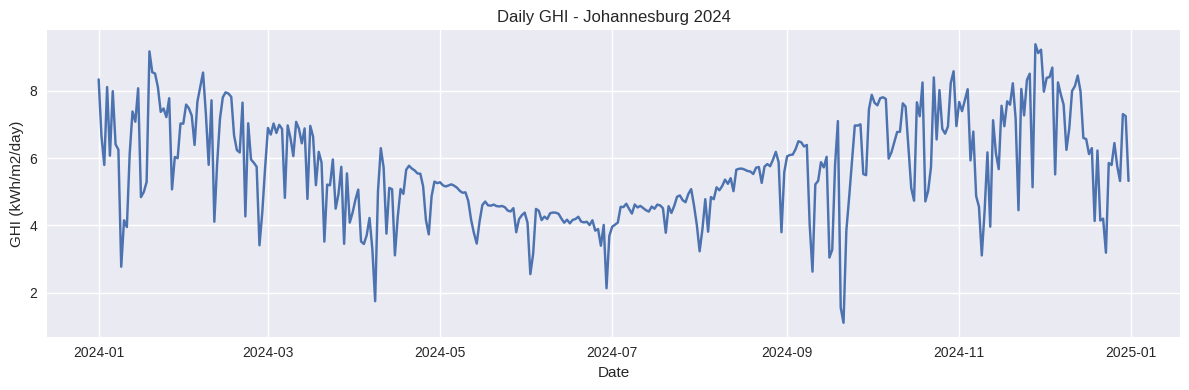

In [8]:
city = "Johannesburg"
df_jhb = df_all[df_all["city"] == city]

plt.figure(figsize=(12,4))
plt.plot(df_jhb["date"], df_jhb["ghi_kwh_m2"])
plt.title(f"Daily GHI - {city} 2024")
plt.xlabel("Date")
plt.ylabel("GHI (kWh/m2/day)")
plt.tight_layout()
plt.show()